# DOUBLE PENDULUM

In [1]:
from matplotlib import pyplot as plt
from matplotlib.animation import PillowWriter
import numpy as np

In [63]:
m = 1.
l = 1.
g = 9.8

tmax = 10.
dt = 0.001

t = np.linspace(0, tmax, int((tmax -0)/dt + 1))

phi1 = np.zeros(len(t))
phi2 = np.zeros(len(t))

phi1[0] = np.pi/2
phi2[0] = np.pi/2

#phi1[0] = 1.
#phi2[0] = 1.

omega1 = np.zeros(len(t))
omega2 = np.zeros(len(t))

#omega1[0] = 0.
#omega2[0] = 2.5
#omega2[0] = 0.5
#omega2[0] = 1.5


phi1_poincare_points = []
omega1_poincare_points = []


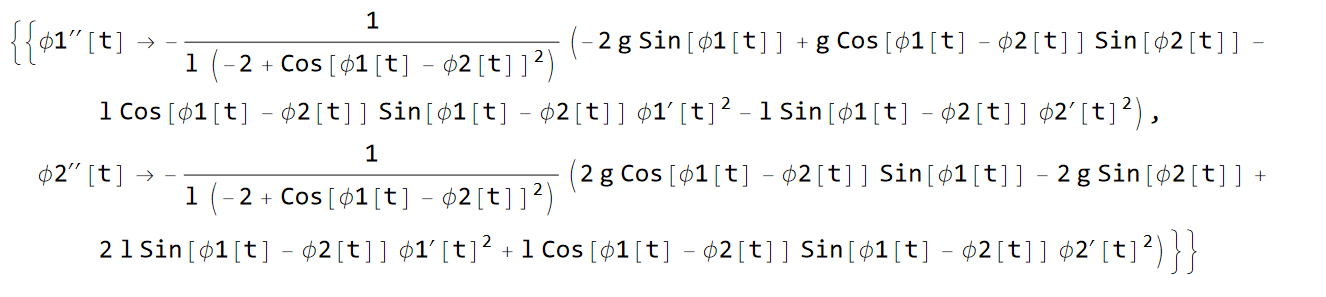

In [64]:
def calc_omegadot_1(phi1, phi2, omega1, omega2):

    return -1.*(-2*g*np.sin(phi1) + g*np.cos(phi1 - phi2)*np.sin(phi2) - l*np.cos(phi1 - phi2)*np.sin(phi1 - phi2)*omega1**2 - l*np.sin(phi1 - phi2)*omega2**2)/(l*(-2 + np.cos(phi1 - phi2)**2))

def calc_omegadot_2(phi1, phi2, omega1, omega2):

    return -1.*(2*g*np.cos(phi1 - phi2)*np.sin(phi1) - 2*g*np.sin(phi2) + 2*l*np.sin(phi1 - phi2)*omega1**2 +l*np.cos(phi1 - phi2)*np.sin(phi1 - phi2)*omega2**2)/(l*(-2 + np.cos(phi1 - phi2)**2))



In [65]:
for i in range(0, len(t)-1):

    k1_omega1 = calc_omegadot_1(phi1[i], phi2[i], omega1[i], omega2[i])
    k1_omega2 = calc_omegadot_2(phi1[i], phi2[i], omega1[i], omega2[i])
    k1_phi1 = omega1[i]
    k1_phi2 = omega2[i]
 #######################################################################################
    omega1_d = omega1[i] + k1_omega1*dt/2
    omega2_d = omega2[i] + k1_omega2*dt/2
    phi1_d = phi1[i] + k1_phi1*dt/2
    phi2_d = phi2[i] + k1_phi2*dt/2

    k2_omega1 = calc_omegadot_1(phi1_d, phi2_d, omega1_d, omega2_d)
    k2_omega2 = calc_omegadot_2(phi1_d, phi2_d, omega1_d, omega2_d)
    k2_phi1 = omega1_d
    k2_phi2 = omega2_d
 #######################################################################################
    omega1_d = omega1[i] + k2_omega1*dt/2
    omega2_d = omega2[i] + k2_omega2*dt/2
    phi1_d = phi1[i] + k2_phi1*dt/2
    phi2_d = phi2[i] + k2_phi2*dt/2

    k3_omega1 = calc_omegadot_1(phi1_d, phi2_d, omega1_d, omega2_d)
    k3_omega2 = calc_omegadot_2(phi1_d, phi2_d, omega1_d, omega2_d)
    k3_phi1 = omega1_d
    k3_phi2 = omega2_d
 #######################################################################################
    omega1_d = omega1[i] + k3_omega1*dt
    omega2_d = omega2[i] + k3_omega2*dt
    phi1_d = phi1[i] + k3_phi1*dt
    phi2_d = phi2[i] + k3_phi2*dt

    k4_omega1 = calc_omegadot_1(phi1_d, phi2_d, omega1_d, omega2_d)
    k4_omega2 = calc_omegadot_2(phi1_d, phi2_d, omega1_d, omega2_d)
    k4_phi1 = omega1_d
    k4_phi2 = omega2_d
 #######################################################################################
    omega1[i+1] = omega1[i] + (1/6)*(k1_omega1 + 2*k2_omega1 + 2*k3_omega1 + k4_omega1)*dt
    omega2[i+1] = omega2[i] + (1/6)*(k1_omega2 + 2*k2_omega2 + 2*k3_omega2 + k4_omega2)*dt

    phi1[i+1] = phi1[i] + (1/6)*(k1_phi1 + 2*k2_phi1 + 2*k3_phi1 + k4_phi1)*dt
    phi2[i+1] = phi2[i] + (1/6)*(k1_phi2 + 2*k2_phi2 + 2*k3_phi2 + k4_phi2)*dt

    if phi1[i+1]>np.pi:
        phi1[i+1] = phi1[i+1] - 2*np.pi
    elif phi1[i+1]<-np.pi:
        phi1[i+1] = phi1[i+1] + 2*np.pi

    if phi2[i+1]>np.pi:
        phi2[i+1] = phi2[i+1] - 2*np.pi
    elif phi2[i+1]<-np.pi:
        phi2[i+1] = phi2[i+1] + 2*np.pi
    
    if phi2[i+1]*phi2[i]<0 and omega2[i+1] > 0:
        phi1_poincare_points.append(phi1[i+1])
        omega1_poincare_points.append(omega1[i+1])

    

# Calculate Energy


In [66]:
#Cartesian Quantities

x1 = l*np.sin(phi1)
y1 = 2*l - l*np.cos(phi1)
vx1 = l*np.cos(phi1)*omega1
vy1 = l*np.sin(phi1)*omega1

x2 = x1 + l*np.sin(phi2)
y2 = y1  - l*np.cos(phi2)
vx2 = vx1 + l*np.cos(phi2)*omega2
vy2 = vy1 + l*np.sin(phi2)*omega2

In [67]:
E = (1/2)*m*(vx1**2 + vy1**2) + (1/2)*m*(vx2**2 + vy2**2) + m*g*y1 + m*g*y2

C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_7216\2724814971.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.plot(t,np.log10(np.abs(E/E[0]-1)))


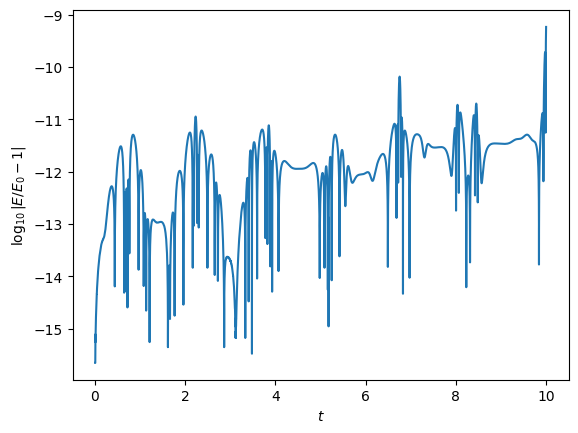

In [68]:
plt.plot(t,np.log10(np.abs(E/E[0]-1)))
plt.xlabel(r'$t$')
plt.ylabel(r'$\log_{10}|E/E_0-1$|')
plt.show()

## Gif Animation

In [8]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)



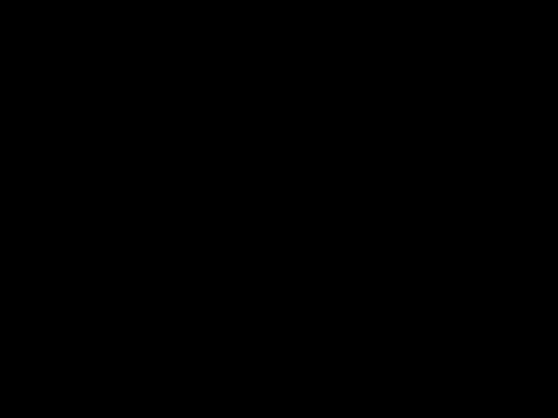

In [9]:

fig, ax = plt.subplots()
fig.patch.set_facecolor('black')

with writer.saving(fig, 'double_pendulum.gif',100):
    for i in range(0, len(t)):
        if i%50 == 0:
            ax.set_facecolor('black')
            ax.plot([0,x1[i]],[2*l,y1[i]], c='red', linewidth=1)
            ax.plot([x1[i], x2[i]], [y1[i], y2[i]], c='blue', linewidth=1)

            ax.scatter(x1[i],y1[i],c = 'red')
            ax.scatter(x2[i], y2[i], c='blue')
            
            #The time
            ax.annotate(f'Time: {t[i]:.2f} s', (-1.75, 1.75), c='white')

            
            ax.set_xlim([-2*l,2*l])
            ax.set_ylim([-0.1,4*l+0.1])
            ax.set_xticks([])
            ax.set_yticks([])
            
            writer.grab_frame()
            ax.clear()
